# KNN y Naive Bayes

Pruebas reproducibles con la misma separación train/validación, grupos y métricas de modeling.ipynb. El conjunto test.pkl se reserva para la evaluación final.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.impute import SimpleImputer
from sklearn.metrics import average_precision_score, classification_report, confusion_matrix
from sklearn.naive_bayes import BernoulliNB, MultinomialNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler

sys.path.insert(0, str(Path.cwd().parent))
from config import config
from utils.evaluador_cv import EvaluadorCV

sklearn.set_config(enable_metadata_routing=True)
DIR_SPLITS = config.DATADIR / 'splits'
archivos_splits = {
    nombre: DIR_SPLITS / f'{nombre}.pkl'
    for nombre in ('train', 'val', 'test')
}
faltantes = [str(ruta) for ruta in archivos_splits.values() if not ruta.exists()]
if faltantes:
    raise FileNotFoundError(
        'No existen las particiones de modelado:\n- '
        + '\n- '.join(faltantes)
        + '\n\nEjecute primero la celda 128 de eda_consolidate.ipynb '
        'para crear data/splits/train.pkl, val.pkl y test.pkl.'
    )

df_train = pd.read_pickle(archivos_splits['train'])
df_val = pd.read_pickle(archivos_splits['val'])
assert list(df_train.columns) == list(df_val.columns)

LLAVES = ['DIRECTORIO', 'SECUENCIA_P']
GRUPO, PESO, OBJETIVO = 'SEGMENTO', 'PESO', 'POBRE'
CARACTERISTICAS = [
    c for c in df_train.columns
    if c not in [*LLAVES, GRUPO, PESO, OBJETIVO]
]


In [2]:
X_train, y_train = df_train[CARACTERISTICAS], df_train[OBJETIVO]
grupos_train = df_train[GRUPO]
X_val, y_val = df_val[CARACTERISTICAS], df_val[OBJETIVO]

pd.DataFrame(
    {'hogares': [len(df_train), len(df_val)],
     'tasa POBRE': [y_train.mean(), y_val.mean()]},
    index=['train', 'val'],
)


,hogares,tasa POBRE
train,31039,0.128419
val,6643,0.128707


## K vecinos más cercanos (KNN)

KNN se ajusta después de imputar y escalar al intervalo [0, 1], pues su distancia depende de la escala. Para contener la dimensionalidad, se retienen dentro de cada pliegue las 10 variables con mayor información mutua. Se elige el mejor candidato por average precision (PR-AUC), más informativa que accuracy cuando POBRE está desbalanceada.

In [3]:
N_FEATURES = min(10, X_train.shape[1])

def crear_knn(n_vecinos):
    return Pipeline(
        [('imputer', SimpleImputer(
            strategy='constant', fill_value=0, add_indicator=True
        )),
         ('scaler', MinMaxScaler()),
         ('select_vars', SelectKBest(mutual_info_classif, k=N_FEATURES)),
         ('model', KNeighborsClassifier(
             n_neighbors=n_vecinos, weights='distance', n_jobs=-1
         ))]
    )

knn_candidatos = {k: crear_knn(k) for k in (5, 15, 31)}


In [4]:
evaluaciones_knn, resumen_knn = {}, []

for k, modelo in knn_candidatos.items():
    ev = EvaluadorCV(
        modelo, X_train, y_train, 0.5, grupos_train, pickle=True
    ).evaluar_cv()
    evaluaciones_knn[k] = ev
    resumen_knn.append({
        'n_neighbors': k,
        'average_precision': np.mean(
            ev.scores['test_average_precision']
        ),
        'recall': np.mean(ev.scores['test_recall']),
        'precision': np.mean(ev.scores['test_precision']),
    })

resumen_knn = pd.DataFrame(resumen_knn).sort_values(
    'average_precision', ascending=False
)
resumen_knn


umbral: 0.5
Resultados cargados de caché: C:\Users\USER\Documents\GitHub\Multidimesional_poverty_in_Colombia\data\cache_cv\b490ae00a74d43e464d72d588e0c2849.pkl
umbral: 0.5
Resultados cargados de caché: C:\Users\USER\Documents\GitHub\Multidimesional_poverty_in_Colombia\data\cache_cv\3d6857aba219f3040a27ede083161691.pkl
umbral: 0.5
Resultados cargados de caché: C:\Users\USER\Documents\GitHub\Multidimesional_poverty_in_Colombia\data\cache_cv\424be2b7aab6880e457381bc134dcbcd.pkl


,n_neighbors,average_precision,recall,precision
2,31,0.226100,0.071700,0.504953
1,15,0.208809,0.073511,0.499306
0,5,0.188949,0.092796,0.464469


Mejor K según average precision: 31
fit_time: 0.627 ± 0.054
score_time: 0.738 ± 0.026
test_accuracy: 0.872 ± 0.001
test_precision: 0.505 ± 0.024
test_recall: 0.072 ± 0.027
test_kappa: 0.095 ± 0.031
test_average_precision: 0.226 ± 0.014
--- Frecuencia de selección de variables (5 Folds) ---
                             Variable  Frecuencia  Porcentaje
                    ORG_analfabetismo           5       100.0
              ORG_fuente_agua_cocinar           5       100.0
               ORG_servicio_sanitario           5       100.0
                   ORG_alcantarillado           5       100.0
missingindicator_ORG_trabajo_infantil           5       100.0
                 ORG_trabajo_infantil           4        80.0
                ORG_sin_aseguramiento           3        60.0
                        ORG_acueducto           3        60.0
Matriz de confusión:
 [[26770   283]
 [ 3700   286]]


<Axes: xlabel='Predicted label', ylabel='True label'>

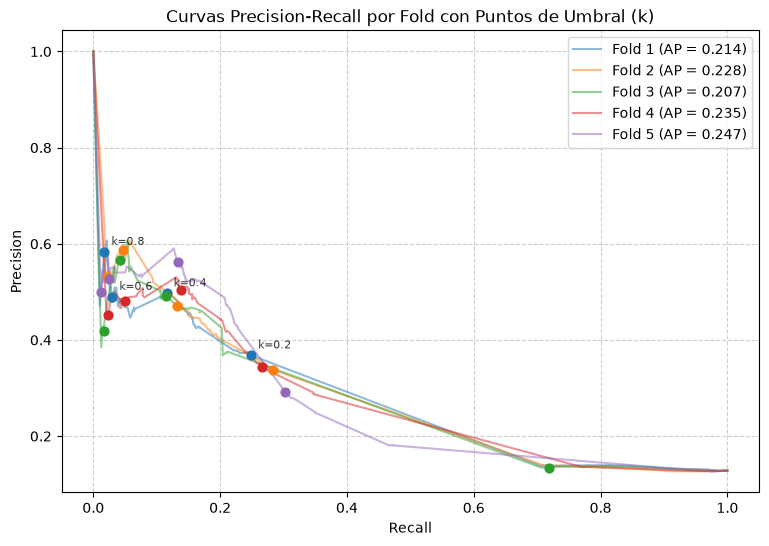

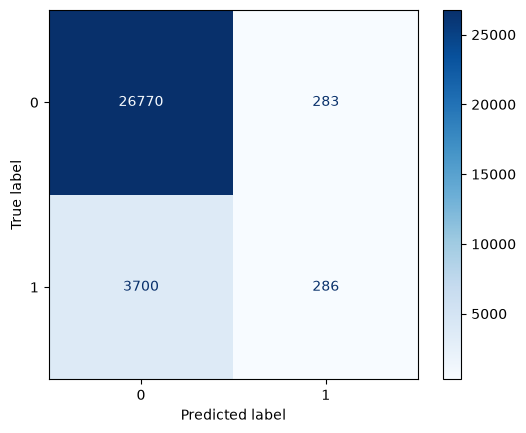

In [5]:
mejor_k = int(resumen_knn.iloc[0]['n_neighbors'])
ev_knn = evaluaciones_knn[mejor_k]
print(f'Mejor K según average precision: {mejor_k}')
ev_knn.resumen_metricas()
ev_knn.frecuencia_variables()
ev_knn.curvas_pr()
ev_knn.matriz_confusion()


## Naive Bayes

BernoulliNB es la versión binomial y se restringe a variables que en entrenamiento son exactamente 0/1. MultinomialNB requiere entradas no negativas, por lo que se imputa y escala toda la matriz. Se incluye como contraste, pero las proporciones y códigos ordinales no son conteos estrictos: si no mejora claramente, BernoulliNB o KNN tienen mejor correspondencia con las variables.

In [6]:
def es_binaria(serie):
    valores = set(serie.dropna().unique())
    return bool(valores) and valores <= {0, 1}

columnas_binarias = [c for c in X_train if es_binaria(X_train[c])]
print(f'Variables binarias 0/1: {len(columnas_binarias)} de {X_train.shape[1]}')

if columnas_binarias:
    bernoulli_nb = Pipeline(
        [('select_binary', ColumnTransformer(
            [('binary', 'passthrough', columnas_binarias)], remainder='drop'
        )),
         ('imputer', SimpleImputer(strategy='constant', fill_value=0)),
         ('model', BernoulliNB(alpha=1.0))]
    )
else:
    print('BernoulliNB binariza en 0: no hay predictores estrictamente binarios.')
    bernoulli_nb = Pipeline(
        [('imputer', SimpleImputer(strategy='constant', fill_value=0)),
         ('scaler', MinMaxScaler()),
         ('model', BernoulliNB(alpha=1.0, binarize=0.0))]
    )

multinomial_nb = Pipeline(
    [('imputer', SimpleImputer(strategy='constant', fill_value=0)),
     ('scaler', MinMaxScaler()),
     ('model', MultinomialNB(alpha=1.0))]
)


Variables binarias 0/1: 0 de 7
BernoulliNB binariza en 0: no hay predictores estrictamente binarios.


In [7]:
evaluaciones_nb, resumen_nb = {}, []
modelos_nb = {
    'BernoulliNB (solo 0/1)': bernoulli_nb,
    'MultinomialNB (no negativas)': multinomial_nb,
}

for nombre, modelo in modelos_nb.items():
    ev = EvaluadorCV(
        modelo, X_train, y_train, 0.5, grupos_train, pickle=True
    ).evaluar_cv()
    evaluaciones_nb[nombre] = ev
    resumen_nb.append({
        'modelo': nombre,
        'average_precision': np.mean(
            ev.scores['test_average_precision']
        ),
        'recall': np.mean(ev.scores['test_recall']),
        'precision': np.mean(ev.scores['test_precision']),
    })

resumen_nb = pd.DataFrame(resumen_nb).sort_values(
    'average_precision', ascending=False
)
resumen_nb


umbral: 0.5


Resultados guardados en caché: C:\Users\USER\Documents\GitHub\Multidimesional_poverty_in_Colombia\data\cache_cv\d58b8137bb14feb49a3f5f5c677b031e.pkl
umbral: 0.5


Resultados guardados en caché: C:\Users\USER\Documents\GitHub\Multidimesional_poverty_in_Colombia\data\cache_cv\391de419b336c7fb9c581a7675c8815f.pkl


,modelo,average_precision,recall,precision
0,BernoulliNB (solo 0/1),0.221723,0.112414,0.405903
1,MultinomialNB (no negativas),0.199063,0.000000,0.000000


Mejor Naive Bayes según average precision: BernoulliNB (solo 0/1)
fit_time: 0.012 ± 0.002
score_time: 0.010 ± 0.000
test_accuracy: 0.859 ± 0.015
test_precision: 0.406 ± 0.119
test_recall: 0.112 ± 0.019
test_kappa: 0.116 ± 0.017
test_average_precision: 0.222 ± 0.018
Matriz de confusión:
 [[26221   832]
 [ 3538   448]]


<Axes: xlabel='Predicted label', ylabel='True label'>

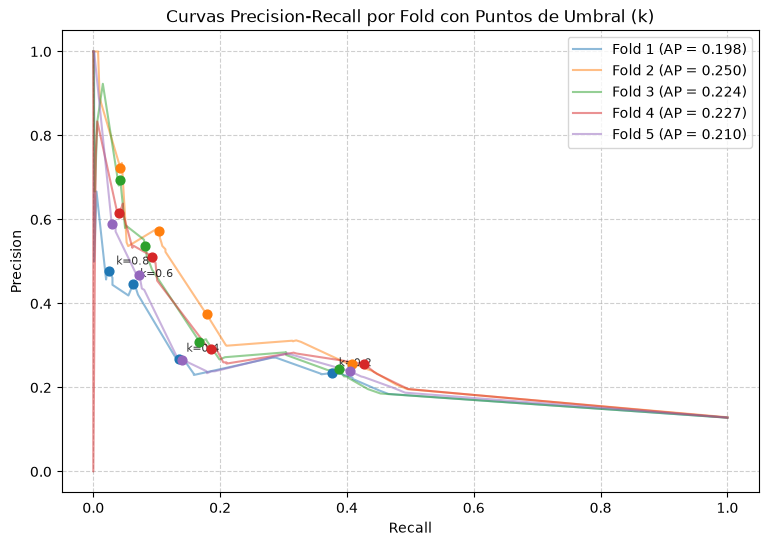

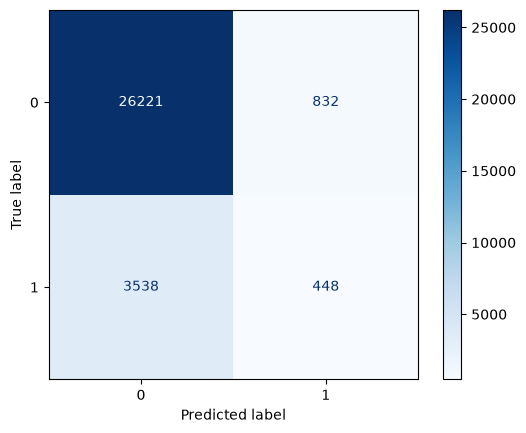

In [8]:
mejor_nb = resumen_nb.iloc[0]['modelo']
ev_nb = evaluaciones_nb[mejor_nb]
print(f'Mejor Naive Bayes según average precision: {mejor_nb}')
ev_nb.resumen_metricas()
ev_nb.curvas_pr()
ev_nb.matriz_confusion()


## Validación externa

Tras seleccionar el modelo y el umbral con la validación cruzada, se ajusta sobre todo train y se mide una sola vez en validación. Se reportan los mejores KNN y Naive Bayes para comparar; test.pkl no se usa en esta etapa.

In [9]:
candidatos_finales = {
    f'KNN (k={mejor_k})': ev_knn,
    mejor_nb: ev_nb,
}
resultados_val = []

for nombre, evaluacion in candidatos_finales.items():
    modelo_final = evaluacion.ajustar_final()
    proba_val = modelo_final.predict_proba(X_val)[:, 1]
    pred_val = (proba_val >= 0.5).astype(int)
    resultados_val.append({
        'modelo': nombre,
        'average_precision': average_precision_score(y_val, proba_val),
        'matriz_confusion': confusion_matrix(y_val, pred_val).tolist(),
    })
    print(f'\n{nombre}')
    print(classification_report(y_val, pred_val, zero_division=0))

pd.DataFrame(resultados_val).sort_values('average_precision', ascending=False)



KNN (k=31)
              precision    recall  f1-score   support

           0       0.88      0.99      0.93      5788
           1       0.55      0.05      0.09       855

    accuracy                           0.87      6643
   macro avg       0.71      0.52      0.51      6643
weighted avg       0.83      0.87      0.82      6643


BernoulliNB (solo 0/1)
              precision    recall  f1-score   support

           0       0.88      0.99      0.93      5788
           1       0.49      0.09      0.15       855

    accuracy                           0.87      6643
   macro avg       0.69      0.54      0.54      6643
weighted avg       0.83      0.87      0.83      6643



,modelo,average_precision,matriz_confusion
0,KNN (k=31),0.229135,"[[5753, 35], [812, 43]]"
1,BernoulliNB (solo 0/1),0.213953,"[[5711, 77], [780, 75]]"
